# Improving Customer Satisfaction through Automated Review Sentiment Analysis

**Goal:** build an automated system that classifies Amazon product reviews as **Positive** or **Negative**, so the business can monitor product performance in real time, spot sudden spikes of negative feedback, and respond to complaints faster.

**Workflow**

1. Setup & data loading
2. Data cleaning (duplicates, missing values, text preprocessing)
3. Exploratory analysis (class balance, review length, word clouds, most common / most distinctive words, bigrams)
4. Model development (TF-IDF + Logistic Regression / SVM / Naive Bayes, Word2Vec + Logistic Regression / Neural Network)
5. Validation (train/test split, 5-fold cross-validation, accuracy, F1, confusion matrices, hyperparameter tuning)
6. Error analysis & interpretability
7. Final deployable pipeline, business recommendations, limitations

**Dataset:** 10,000 labelled reviews with columns `label` (`pos`/`neg`) and `review` (free text; each review starts with a short title followed by a colon).

## 1. Setup and Data Loading

In [1]:
import re, warnings, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

from wordcloud import WordCloud
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, f1_score, precision_score, recall_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, roc_curve)
from gensim.models import Word2Vec

warnings.filterwarnings("ignore")
SEED = 42                      # one seed everywhere -> reproducible results
random.seed(SEED); np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100
DATA_PATH = "amazonreviews.tsv"   # tab-separated file supplied with the assignment

In [2]:
# The file is tab-separated. Reviews contain quotes, so we disable quote parsing
# to avoid merging several reviews into one cell.
import csv
df = pd.read_csv(DATA_PATH, sep="\t", quoting=csv.QUOTE_NONE, encoding="utf-8")
print("Shape:", df.shape)
df.head()

Shape: (10000, 2)


,label,review
0,pos,Stuning even for the non-gamer: This sound tra...
1,pos,The best soundtrack ever to anything.: I'm rea...
2,pos,"""Amazing!: This soundtrack is my favorite musi..."
3,pos,Excellent Soundtrack: I truly like this soundt...
4,pos,"Remember, Pull Your Jaw Off The Floor After He..."


In [3]:
df.info()
print("\nLabel values:", df["label"].unique())

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   label   10000 non-null  str  
 1   review  10000 non-null  str  
dtypes: str(2)
memory usage: 156.4 KB

Label values: <StringArray>
['pos', 'neg']
Length: 2, dtype: str


## 2. Data Cleaning

Steps: (1) check missing values, (2) remove duplicates, (3) validate labels, (4) preprocess the text — lowercasing, URL/HTML/number/punctuation removal, stop-word removal.

**Design decision – negations are kept.** Standard stop-word lists contain words such as *not, no, nor, never, don't*. In sentiment analysis these flip the meaning (“not good” ≠ “good”), so removing them would damage the model. We therefore remove stop words **except** negations.

In [4]:
# ---- 2.1 Missing values & duplicates ------------------------------------------------
print("Missing values per column:\n", df.isna().sum(), "\n")
print("Empty / whitespace-only reviews:", (df["review"].fillna("").str.strip() == "").sum())
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicated review texts:", df["review"].duplicated().sum())

n_before = len(df)
df = (df.dropna(subset=["review", "label"])              # drop rows with missing text/label
        .assign(review=lambda d: d["review"].str.strip())
        .loc[lambda d: d["review"] != ""]                # drop empty reviews
        .drop_duplicates(subset="review")                # drop duplicate review texts
        .reset_index(drop=True))
print(f"\nRows before: {n_before} | after cleaning: {len(df)} | removed: {n_before - len(df)}")

Missing values per column:
 label     0
review    0
dtype: int64 

Empty / whitespace-only reviews: 0
Fully duplicated rows: 0
Duplicated review texts: 0

Rows before: 10000 | after cleaning: 10000 | removed: 0


In [5]:
# ---- 2.2 Label validation & encoding ----------------------------------------------
assert set(df["label"].unique()) <= {"pos", "neg"}, "Unexpected label found"
df["target"] = (df["label"] == "pos").astype(int)         # 1 = positive, 0 = negative
df["label"].value_counts()

label
neg    5097
pos    4903
Name: count, dtype: int64

In [6]:
# ---- 2.3 Text preprocessing ---------------------------------------------------------
NEGATIONS = {"no", "not", "nor", "never", "none", "nothing", "nobody", "neither", "cannot", "without"}
STOPWORDS = set(ENGLISH_STOP_WORDS) - NEGATIONS            # sklearn's list minus negations

def clean_text(text: str, remove_stopwords: bool = True) -> str:
    """Normalise one review.

    lowercase -> strip URLs/HTML -> expand n't contractions -> keep letters only
    -> (optionally) drop stop words & 1-character tokens.
    """
    text = text.lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)      # URLs
    text = re.sub(r"<[^>]+>", " ", text)                     # HTML tags
    text = re.sub(r"\bcan't\b", "cannot", text)             # can't -> cannot (avoids the odd token "ca")
    text = re.sub(r"\bwon't\b", "will not", text)           # won't -> will not (avoids "wo")
    text = re.sub(r"n't\b", " not", text)                    # don't -> do not, isn't -> is not
    text = re.sub(r"[^a-z\s]", " ", text)                    # digits & punctuation -> space
    tokens = text.split()
    if remove_stopwords:
        tokens = [t for t in tokens if t not in STOPWORDS and len(t) > 1]
    return " ".join(tokens)

example = df["review"].iloc[0]
print("RAW  :", example[:250], "...")
print("CLEAN:", clean_text(example)[:250], "...")

RAW  : Stuning even for the non-gamer: This sound track was beautiful! It paints the senery in your mind so well I would recomend it even to people who hate vid. game music! I have played the game Chrono Cross but out of all of the games I have ever played  ...
CLEAN: stuning non gamer sound track beautiful paints senery mind recomend people hate vid game music played game chrono cross games played best music backs away crude keyboarding takes fresher step grate guitars soulful orchestras impress cares listen ...


In [7]:
df["clean"] = df["review"].apply(clean_text)                       # stop words removed (for EDA, Word2Vec, TF-IDF)
df["clean_with_stop"] = df["review"].apply(lambda t: clean_text(t, remove_stopwords=False))  # kept to test the effect of stop-word removal

# Reviews that became empty after cleaning cannot be modelled
empty = (df["clean"].str.len() == 0).sum()
print("Reviews empty after cleaning:", empty)
df = df[df["clean"].str.len() > 0].reset_index(drop=True)
df[["label", "review", "clean"]].head()

Reviews empty after cleaning: 0


,label,review,clean
0,pos,Stuning even for the non-gamer: This sound tra...,stuning non gamer sound track beautiful paints...
1,pos,The best soundtrack ever to anything.: I'm rea...,best soundtrack reading lot reviews saying bes...
2,pos,"""Amazing!: This soundtrack is my favorite musi...",amazing soundtrack favorite music time hands i...
3,pos,Excellent Soundtrack: I truly like this soundt...,excellent soundtrack truly like soundtrack enj...
4,pos,"Remember, Pull Your Jaw Off The Floor After He...",remember pull jaw floor hearing ve played game...


## 3. Exploratory Data Analysis

### 3.1 Sentiment distribution

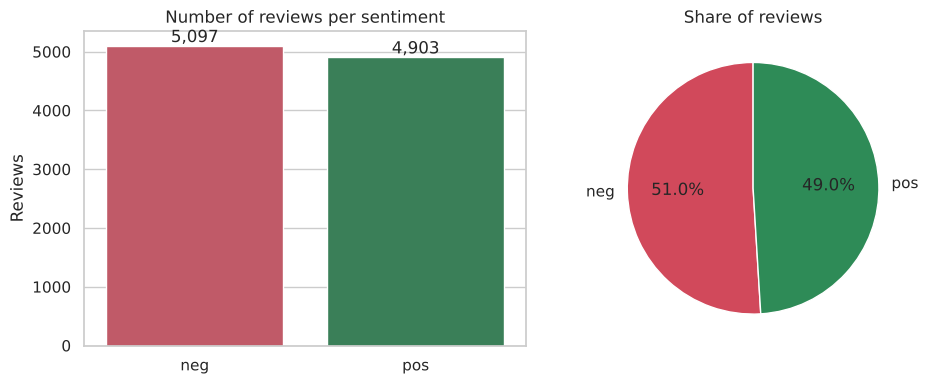

In [8]:
counts = df["label"].value_counts()
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.barplot(x=counts.index, y=counts.values, palette=["#d1495b", "#2e8b57"] if counts.index[0]=="neg" else ["#2e8b57", "#d1495b"], ax=ax[0])
ax[0].set_title("Number of reviews per sentiment"); ax[0].set_xlabel(""); ax[0].set_ylabel("Reviews")
for i, v in enumerate(counts.values):
    ax[0].text(i, v, f"{v:,}", ha="center", va="bottom")
ax[1].pie(counts.values, labels=counts.index, autopct="%1.1f%%", colors=["#d1495b", "#2e8b57"] if counts.index[0]=="neg" else ["#2e8b57", "#d1495b"], startangle=90)
ax[1].set_title("Share of reviews")
plt.tight_layout(); plt.show()

**Insight:** the classes are almost perfectly balanced (~51% negative / ~49% positive). Accuracy is therefore a trustworthy headline metric, and no resampling or class weighting is needed. We still report F1 because the business cares about *both* classes.

### 3.2 Review length

label             neg     pos
n_words count  5097.0  4903.0
        mean     81.7    77.3
        std      42.5    43.5
        min      15.0    14.0
        25%      47.0    40.0
        50%      74.0    68.0
        75%     112.0   106.0
        max     212.0   207.0
n_chars count  5097.0  4903.0
        mean    450.3   428.9
        std     235.8   243.8
        min     101.0   101.0
        25%     253.0   223.0
        50%     408.0   370.0
        75%     616.0   595.0
        max    1019.0  1022.0


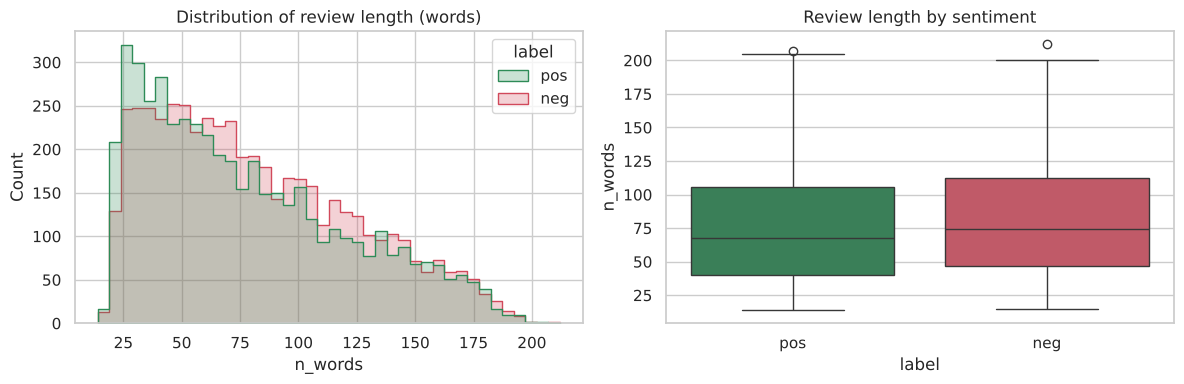

In [9]:
df["n_words"] = df["review"].str.split().str.len()
df["n_chars"] = df["review"].str.len()
print(df.groupby("label")[["n_words", "n_chars"]].describe().T.round(1))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="n_words", hue="label", bins=40, element="step", ax=ax[0], palette={"neg": "#d1495b", "pos": "#2e8b57"})
ax[0].set_title("Distribution of review length (words)")
sns.boxplot(data=df, x="label", y="n_words", ax=ax[1], palette={"neg": "#d1495b", "pos": "#2e8b57"})
ax[1].set_title("Review length by sentiment"); plt.tight_layout(); plt.show()

**Insight:** review length is similar for both classes (about 80 words on average; negative reviews are slightly longer, mean 82 vs 77 words), so length alone is a weak predictor. The signal must come from *which* words are used.

### 3.3 Word clouds

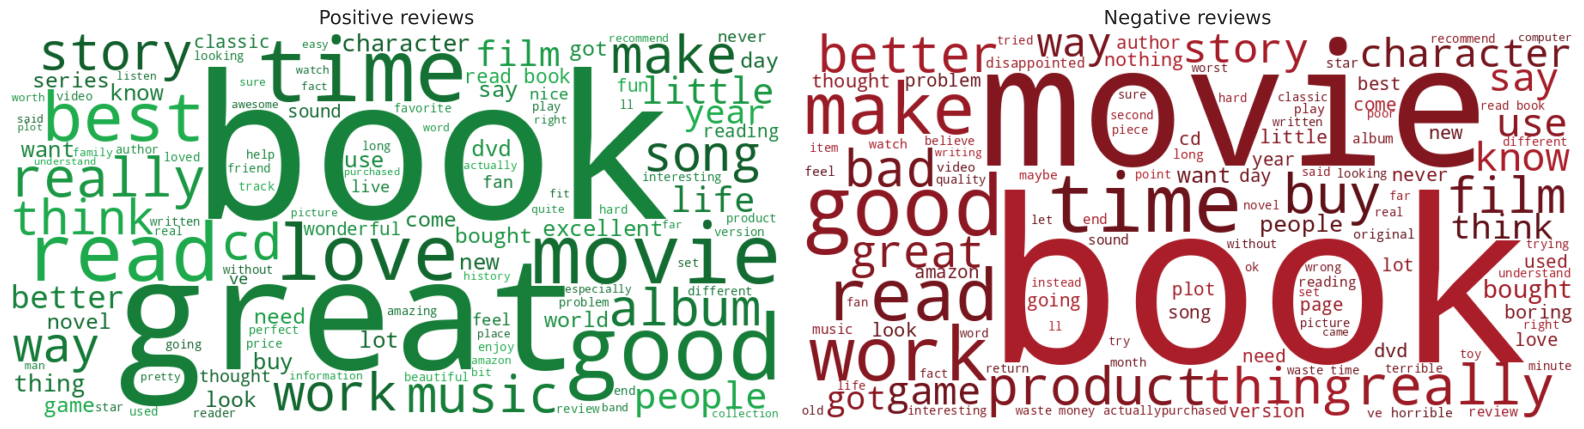

In [10]:
def plot_wordcloud(texts, title, hue, ax):
    # dark, saturated shades of one hue so that even small words stay readable on white
    dark = lambda *a, **k: f"hsl({hue}, 70%, {random.randint(22, 40)}%)"
    wc = WordCloud(width=900, height=450, background_color="white", color_func=dark,
                   max_words=120, prefer_horizontal=1.0, random_state=SEED).generate(" ".join(texts))
    ax.imshow(wc, interpolation="bilinear"); ax.axis("off"); ax.set_title(title, fontsize=14)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
plot_wordcloud(df.loc[df.target == 1, "clean"], "Positive reviews", 140, ax[0])
plot_wordcloud(df.loc[df.target == 0, "clean"], "Negative reviews", 355, ax[1])
plt.tight_layout(); plt.show()

**Insight:** both clouds are dominated by shared *topic* words (book, movie, music, story, read, time) because most reviews are about media products, so word clouds alone separate the classes poorly. The evaluative words are what differ, and the next sections quantify them.

### 3.4 Most common words per sentiment

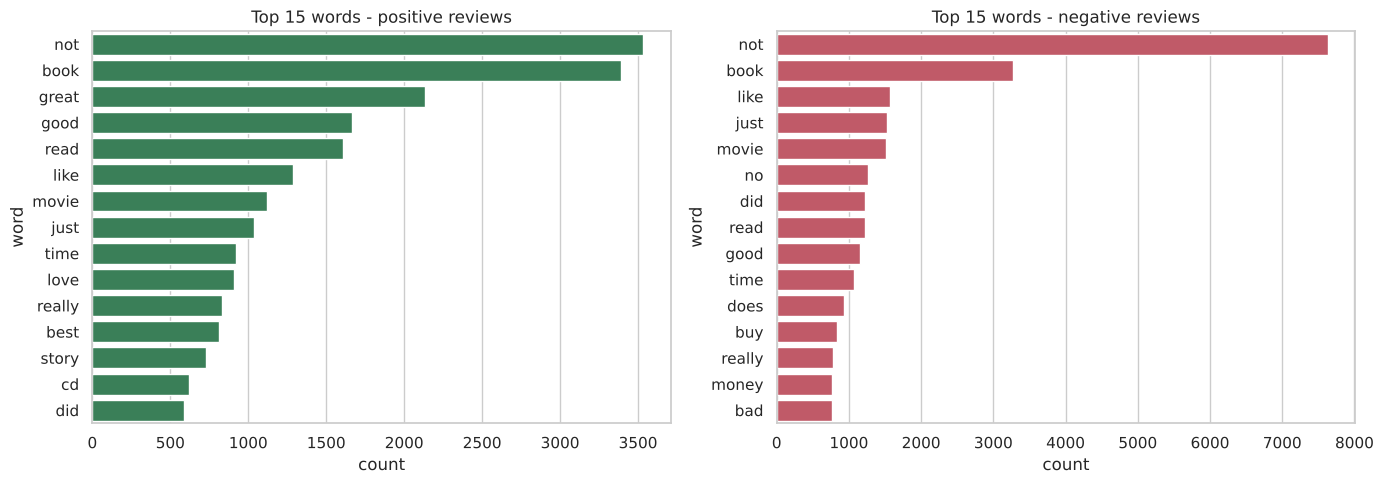

In [11]:
def top_words(texts, n=15):
    c = Counter(w for t in texts for w in t.split())
    return pd.DataFrame(c.most_common(n), columns=["word", "count"])

top_pos = top_words(df.loc[df.target == 1, "clean"])
top_neg = top_words(df.loc[df.target == 0, "clean"])

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=top_pos, y="word", x="count", color="#2e8b57", ax=ax[0]); ax[0].set_title("Top 15 words - positive reviews")
sns.barplot(data=top_neg, y="word", x="count", color="#d1495b", ax=ax[1]); ax[1].set_title("Top 15 words - negative reviews")
plt.tight_layout(); plt.show()

**Insight:** the most frequent words overlap heavily between classes (*book, movie, like, read, good, time*). One exception stands out: **“not” appears about 8,000 times in negative reviews versus about 3,800 in positive ones**, even though the two classes are about the same size, and *no, did, does, money, bad* are also more frequent among negative reviews. This confirms that negation handling matters. Note that “not” is also frequent in positive reviews (e.g. “could not put it down”), so a single word is never enough on its own.

### 3.5 Most *distinctive* words (log-odds ratio)
Raw frequency is dominated by words used by both classes. A smoothed **log-odds ratio** highlights the words that are much more likely in one class than the other.

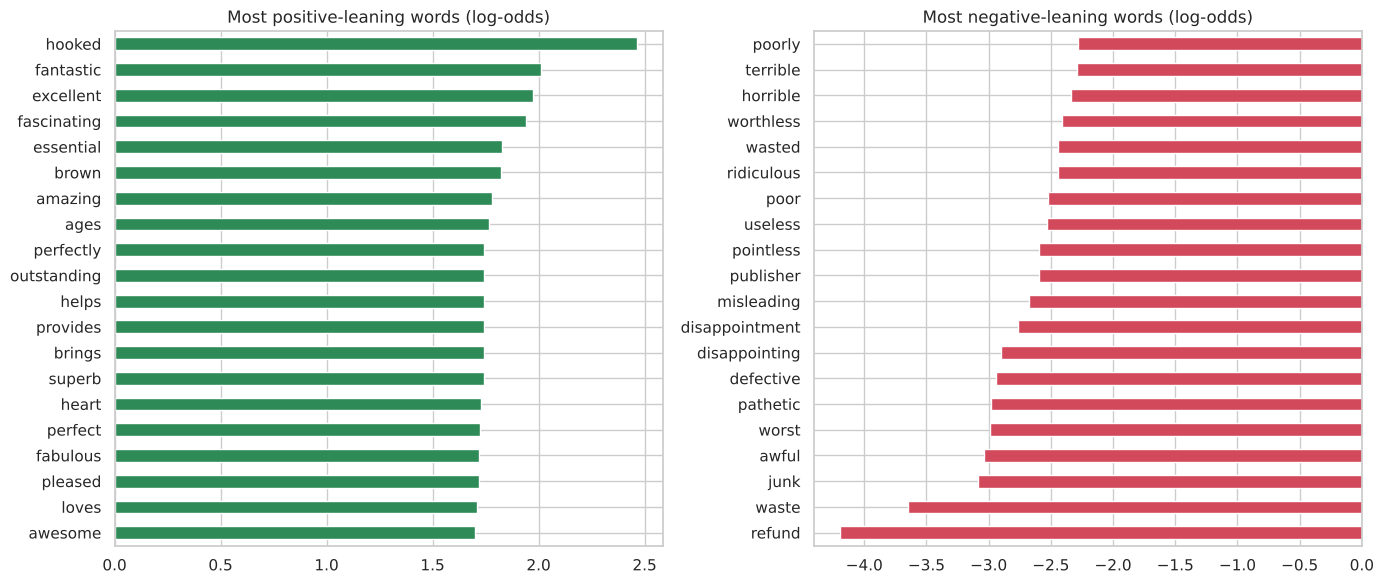

In [12]:
cv = CountVectorizer(min_df=40)                        # ignore rare words (author/character names etc.) -> less noise
X_counts = cv.fit_transform(df["clean"])
vocab = np.array(cv.get_feature_names_out())
pos_c = np.asarray(X_counts[df.target.values == 1].sum(axis=0)).ravel() + 1   # +1 Laplace smoothing
neg_c = np.asarray(X_counts[df.target.values == 0].sum(axis=0)).ravel() + 1
log_odds = np.log(pos_c / pos_c.sum()) - np.log(neg_c / neg_c.sum())

lo = pd.Series(log_odds, index=vocab).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
lo.tail(20).plot.barh(color="#2e8b57", ax=ax[0]); ax[0].set_title("Most positive-leaning words (log-odds)")
lo.head(20).plot.barh(color="#d1495b", ax=ax[1]); ax[1].set_title("Most negative-leaning words (log-odds)")
plt.tight_layout(); plt.show()

**Insight:** the positive side is made of praise words (*fantastic, excellent, amazing, outstanding, superb, perfect, awesome*) and “engagement” words (*hooked, fascinating*). The negative side is dominated by complaints about quality and value: *refund, waste, junk, defective, worst, awful, disappointing, useless, misleading*. A few entries (e.g. *brown, ages, publisher*) are topic words that happen to correlate with a label in this sample; they illustrate the risk of topic leakage in small datasets.

### 3.6 Most common bigrams

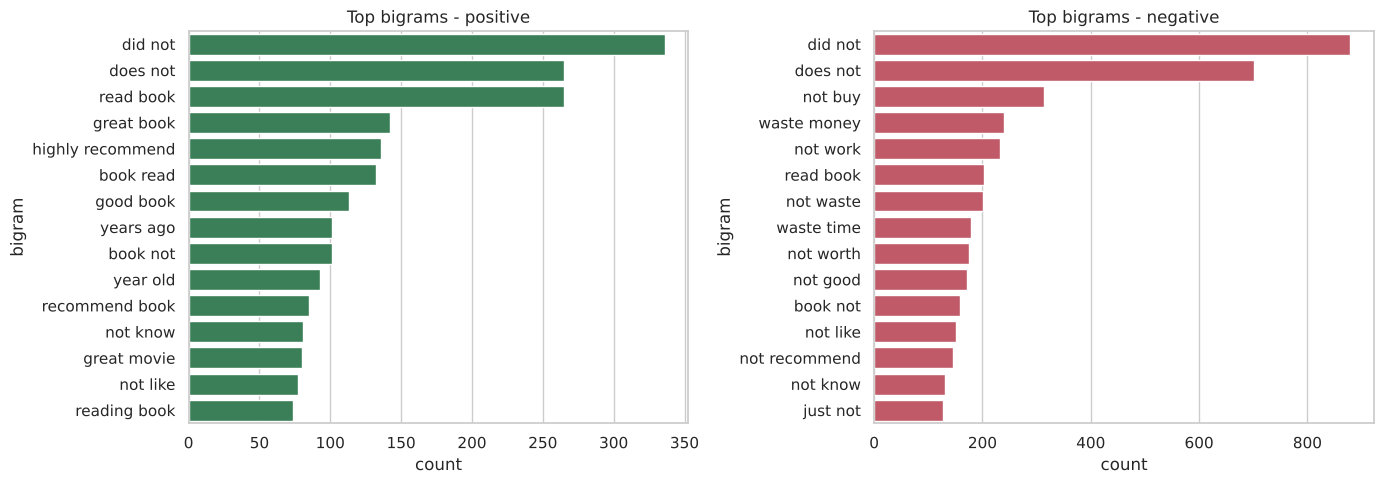

In [13]:
def top_ngrams(texts, ngram=(2, 2), n=15):
    v = CountVectorizer(ngram_range=ngram, min_df=5)
    X = v.fit_transform(texts)
    freq = np.asarray(X.sum(axis=0)).ravel()
    idx = freq.argsort()[::-1][:n]
    return pd.DataFrame({"bigram": np.array(v.get_feature_names_out())[idx], "count": freq[idx]})

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=top_ngrams(df.loc[df.target == 1, "clean"]), y="bigram", x="count", color="#2e8b57", ax=ax[0]); ax[0].set_title("Top bigrams - positive")
sns.barplot(data=top_ngrams(df.loc[df.target == 0, "clean"]), y="bigram", x="count", color="#d1495b", ax=ax[1]); ax[1].set_title("Top bigrams - negative")
plt.tight_layout(); plt.show()

**Insight:** bigrams carry sentiment that single words miss. Positive reviews contain *highly recommend*, *great book*, *good book*; negative reviews contain *waste money*, *waste time*, *not buy*, *not work*, *not worth*, *not good*. Negation bigrams (*did not*, *does not*) are common in **both** classes, but are far more frequent in negative reviews. This motivates including **bigrams** in the TF-IDF features.

## 4. Model Development & Validation Strategy

**Validation design**

* **Hold-out test set:** 20 % of the data, stratified by label, never touched until the final evaluation.
* **5-fold stratified cross-validation** on the 80 % training portion to compare models and tune hyper-parameters robustly.
* **Metrics:** accuracy, precision, recall, F1 (and ROC-AUC).
* **No leakage:** vectorisers are placed *inside* scikit-learn `Pipeline`s so that TF-IDF vocabulary/IDF weights are learned only from the training fold. Word2Vec is likewise trained only on training texts.

**Feature approaches:** TF-IDF (unigrams + bigrams) and Word2Vec (average of word vectors). BERT embeddings were not used: they need a deep-learning stack (PyTorch + a pre-trained model download) that is not available in this environment; they are listed as future work.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["target"], test_size=0.20, stratify=df["target"], random_state=SEED)
# also keep the raw text of the same split for error analysis later
raw_test = df.loc[X_test.index, "review"]

print(f"Train: {len(X_train):,} | Test: {len(X_test):,}")
print("Train positive share:", round(y_train.mean(), 3), "| Test positive share:", round(y_test.mean(), 3))

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = ["accuracy", "f1", "precision", "recall"]

results = []   # collects one row per model for the final comparison table

def evaluate_cv(name, model, X, y):
    """5-fold CV on the training set; stores mean scores in `results`."""
    s = cross_validate(model, X, y, cv=cv5, scoring=scoring, n_jobs=-1)
    row = {"model": name, **{m: s[f"test_{m}"].mean() for m in scoring}, "cv_acc_std": s["test_accuracy"].std()}
    results.append(row)
    return row

Train: 8,000 | Test: 2,000
Train positive share: 0.49 | Test positive share: 0.49


### 4.1 Baseline – does stop-word removal and TF-IDF help?
Quick sanity check with Logistic Regression on three representations of the *same* data.

In [15]:
# Use the same split indices for the stop-words-kept variant
Xtr_sw, Xte_sw = df.loc[X_train.index, "clean_with_stop"], df.loc[X_test.index, "clean_with_stop"]

def lr_pipe(vec): return Pipeline([("vec", vec), ("clf", LogisticRegression(max_iter=2000, random_state=SEED))])

variants = {
  "BoW counts (unigram, stop words removed)": (lr_pipe(CountVectorizer()), X_train),
  "TF-IDF (unigram, stop words removed)":     (lr_pipe(TfidfVectorizer()), X_train),
  "TF-IDF (unigram, stop words KEPT)":        (lr_pipe(TfidfVectorizer()), Xtr_sw),
  "TF-IDF (uni+bigram, stop words removed)":  (lr_pipe(TfidfVectorizer(ngram_range=(1, 2), min_df=2)), X_train),
}
base = []
for name, (pipe, Xtr) in variants.items():
    s = cross_validate(pipe, Xtr, y_train, cv=cv5, scoring=["accuracy", "f1"], n_jobs=-1)
    base.append({"representation": name, "cv_accuracy": s["test_accuracy"].mean(), "cv_f1": s["test_f1"].mean()})
pd.DataFrame(base).round(4)

,representation,cv_accuracy,cv_f1
0,"BoW counts (unigram, stop words removed)",0.8539,0.8524
1,"TF-IDF (unigram, stop words removed)",0.8589,0.8566
2,"TF-IDF (unigram, stop words KEPT)",0.8672,0.8645
3,"TF-IDF (uni+bigram, stop words removed)",0.8642,0.8613


**Takeaway:** TF-IDF beats raw counts (+0.5 pt), and adding bigrams helps further (+0.5 pt). Interestingly, *keeping* stop words scored best among the unigram variants (about +0.8 pt): function words such as *was, very, too, but* carry a little sentiment signal. We still apply stop-word removal because the assignment requires it, it gives cleaner and more interpretable features for the EDA, and the cost is small. A production system could reasonably keep them. We continue with **TF-IDF (1–2 grams)**, which the tuning step below refines.

### 4.2 TF-IDF models: Logistic Regression, Linear SVM, Naive Bayes

In [16]:
tfidf = lambda: TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)

tfidf_models = {
    "TF-IDF + Logistic Regression": Pipeline([("vec", tfidf()), ("clf", LogisticRegression(max_iter=2000, random_state=SEED))]),
    "TF-IDF + Linear SVM":          Pipeline([("vec", tfidf()), ("clf", LinearSVC(random_state=SEED))]),
    "TF-IDF + Naive Bayes":         Pipeline([("vec", tfidf()), ("clf", MultinomialNB())]),
}
for name, model in tfidf_models.items():
    evaluate_cv(name, model, X_train, y_train)
pd.DataFrame(results).round(4)

,model,accuracy,f1,precision,recall,cv_acc_std
0,TF-IDF + Logistic Regression,0.8679,0.8653,0.8653,0.8654,0.0076
1,TF-IDF + Linear SVM,0.8754,0.8739,0.8675,0.8804,0.0051
2,TF-IDF + Naive Bayes,0.8606,0.8535,0.8808,0.8279,0.0076


### 4.3 Hyper-parameter tuning (grid search with 5-fold CV)
We tune the two strongest linear models. The grid covers regularisation strength `C` and the n-gram range / minimum document frequency of the vectoriser.

In [17]:
param_grid_lr = {
    "vec__ngram_range": [(1, 1), (1, 2)],
    "vec__min_df": [1, 2, 5],
    "clf__C": [0.5, 1, 3, 10, 30],
}
gs_lr = GridSearchCV(
    Pipeline([("vec", TfidfVectorizer(sublinear_tf=True)), ("clf", LogisticRegression(max_iter=3000, random_state=SEED))]),
    param_grid_lr, cv=cv5, scoring="accuracy", n_jobs=-1)
gs_lr.fit(X_train, y_train)
print("Best LR params:", gs_lr.best_params_, "| CV accuracy: %.4f" % gs_lr.best_score_)

param_grid_svm = {
    "vec__ngram_range": [(1, 1), (1, 2)],
    "vec__min_df": [1, 2, 5],
    "clf__C": [0.05, 0.1, 0.3, 1, 3],
}
gs_svm = GridSearchCV(
    Pipeline([("vec", TfidfVectorizer(sublinear_tf=True)), ("clf", LinearSVC(random_state=SEED))]),
    param_grid_svm, cv=cv5, scoring="accuracy", n_jobs=-1)
gs_svm.fit(X_train, y_train)
print("Best SVM params:", gs_svm.best_params_, "| CV accuracy: %.4f" % gs_svm.best_score_)

evaluate_cv("TF-IDF + Logistic Regression (tuned)", gs_lr.best_estimator_, X_train, y_train)
evaluate_cv("TF-IDF + Linear SVM (tuned)", gs_svm.best_estimator_, X_train, y_train)

Best LR params: {'clf__C': 10, 'vec__min_df': 2, 'vec__ngram_range': (1, 2)} | CV accuracy: 0.8779


Best SVM params: {'clf__C': 3, 'vec__min_df': 1, 'vec__ngram_range': (1, 2)} | CV accuracy: 0.8771


{'model': 'TF-IDF + Linear SVM (tuned)',
 'accuracy': np.float64(0.877125),
 'f1': np.float64(0.8746537537499437),
 'precision': np.float64(0.8749177695618906),
 'recall': np.float64(0.8745567398934095),
 'cv_acc_std': np.float64(0.007911621199223324)}

### 4.4 Word2Vec embeddings + classifiers

Word2Vec represents each word as a dense vector so that words used in similar contexts are close together. A review is represented by the **average of its word vectors**. Because we only have 10 000 short reviews, we **train Word2Vec ourselves on the training reviews only** (no leakage, no external download). With such a small corpus, we expect these embeddings to be weaker than TF-IDF.

In [18]:
# Tokenise the training reviews and train a skip-gram Word2Vec model
train_tokens = [t.split() for t in X_train]
w2v = Word2Vec(sentences=train_tokens, vector_size=150, window=6, min_count=2,
               sg=1, epochs=30, workers=1, seed=SEED)      # workers=1 -> deterministic
print("Vocabulary size:", len(w2v.wv))

# Sanity check: nearest neighbours should be semantically sensible
for w in ["great", "terrible", "boring"]:
    if w in w2v.wv:
        print(w, "->", [x for x, _ in w2v.wv.most_similar(w, topn=6)])

Vocabulary size: 14164
great -> ['good', 'pur', 'excelent', 'holdin', 'techo', 'genuinely']
terrible -> ['scripting', 'terible', 'flops', 'nutritious', 'motivational', 'frost']
boring -> ['tira', 'rediculously', 'intending', 'breathtakingly', 'uber', 'consisted']


In [19]:
def doc_vector(text, wv=w2v.wv):
    """Average the vectors of all in-vocabulary words of a review (zeros if none)."""
    vecs = [wv[w] for w in text.split() if w in wv]
    return np.mean(vecs, axis=0) if vecs else np.zeros(wv.vector_size)

Xtr_w2v = np.vstack([doc_vector(t) for t in X_train])
Xte_w2v = np.vstack([doc_vector(t) for t in X_test])
print("Embedding matrix shapes:", Xtr_w2v.shape, Xte_w2v.shape)

# Scale features inside the pipeline (fit on training folds only)
from sklearn.preprocessing import StandardScaler
w2v_models = {
    "Word2Vec + Logistic Regression": Pipeline([("sc", StandardScaler()), ("clf", LogisticRegression(max_iter=3000, random_state=SEED))]),
    "Word2Vec + Neural Network (MLP)": Pipeline([("sc", StandardScaler()),
        ("clf", MLPClassifier(hidden_layer_sizes=(128, 64), alpha=1e-1, early_stopping=True,
                              max_iter=300, random_state=SEED))]),
}
# Note: the Word2Vec model saw all training texts, so CV on embeddings is very slightly optimistic;
# the hold-out test set below remains fully unbiased.
for name, model in w2v_models.items():
    evaluate_cv(name, model, Xtr_w2v, y_train)

Embedding matrix shapes: (8000, 150) (2000, 150)


### 4.5 Cross-validated comparison

,accuracy,f1,precision,recall,cv_acc_std
model,,,,,
TF-IDF + Logistic Regression (tuned),0.8779,0.8760,0.8721,0.8802,0.0075
TF-IDF + Linear SVM (tuned),0.8771,0.8747,0.8749,0.8746,0.0079
TF-IDF + Linear SVM,0.8754,0.8739,0.8675,0.8804,0.0051
TF-IDF + Logistic Regression,0.8679,0.8653,0.8653,0.8654,0.0076
TF-IDF + Naive Bayes,0.8606,0.8535,0.8808,0.8279,0.0076
Word2Vec + Logistic Regression,0.8459,0.8431,0.8418,0.8445,0.0144
Word2Vec + Neural Network (MLP),0.8430,0.8393,0.8432,0.8358,0.0144


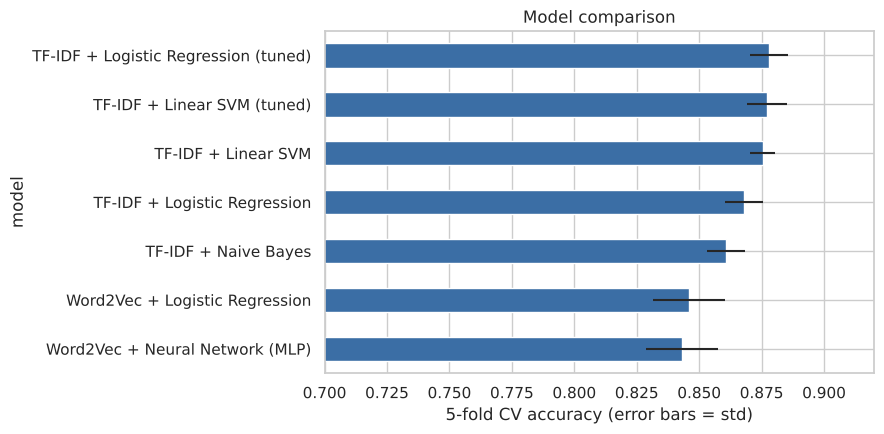

In [20]:
cv_table = pd.DataFrame(results).set_index("model").sort_values("accuracy", ascending=False)
display(cv_table.round(4))

fig, ax = plt.subplots(figsize=(9, 4.5))
cv_table["accuracy"].sort_values().plot.barh(color="#3b6ea5", xerr=cv_table.loc[cv_table["accuracy"].sort_values().index, "cv_acc_std"], ax=ax)
ax.set_xlim(0.7, 0.92); ax.set_xlabel("5-fold CV accuracy (error bars = std)"); ax.set_title("Model comparison")
plt.tight_layout(); plt.show()

## 5. Final Evaluation on the Hold-out Test Set
All models are refit on the full training set and scored **once** on the unseen 20 % test set.

In [21]:
final_models = {
    "TF-IDF + Logistic Regression (tuned)": gs_lr.best_estimator_,
    "TF-IDF + Linear SVM (tuned)":          gs_svm.best_estimator_,
    "TF-IDF + Naive Bayes":                 tfidf_models["TF-IDF + Naive Bayes"],
}
test_rows, preds = [], {}
for name, m in final_models.items():
    m.fit(X_train, y_train)
    p = m.predict(X_test); preds[name] = p
    test_rows.append({"model": name, "accuracy": accuracy_score(y_test, p), "precision": precision_score(y_test, p),
                      "recall": recall_score(y_test, p), "f1": f1_score(y_test, p)})
for name, m in w2v_models.items():
    m.fit(Xtr_w2v, y_train)
    p = m.predict(Xte_w2v); preds[name] = p
    test_rows.append({"model": name, "accuracy": accuracy_score(y_test, p), "precision": precision_score(y_test, p),
                      "recall": recall_score(y_test, p), "f1": f1_score(y_test, p)})

test_table = pd.DataFrame(test_rows).set_index("model").sort_values("f1", ascending=False)
display(test_table.round(4))
best_name = test_table.index[0]
print("Best model on the test set:", best_name)

,accuracy,precision,recall,f1
model,,,,
TF-IDF + Logistic Regression (tuned),0.8695,0.8719,0.8603,0.8661
TF-IDF + Linear SVM (tuned),0.8685,0.8701,0.8603,0.8652
TF-IDF + Naive Bayes,0.8435,0.8703,0.8002,0.8338
Word2Vec + Neural Network (MLP),0.8265,0.8288,0.8145,0.8216
Word2Vec + Logistic Regression,0.8210,0.8208,0.8124,0.8166


Best model on the test set: TF-IDF + Logistic Regression (tuned)


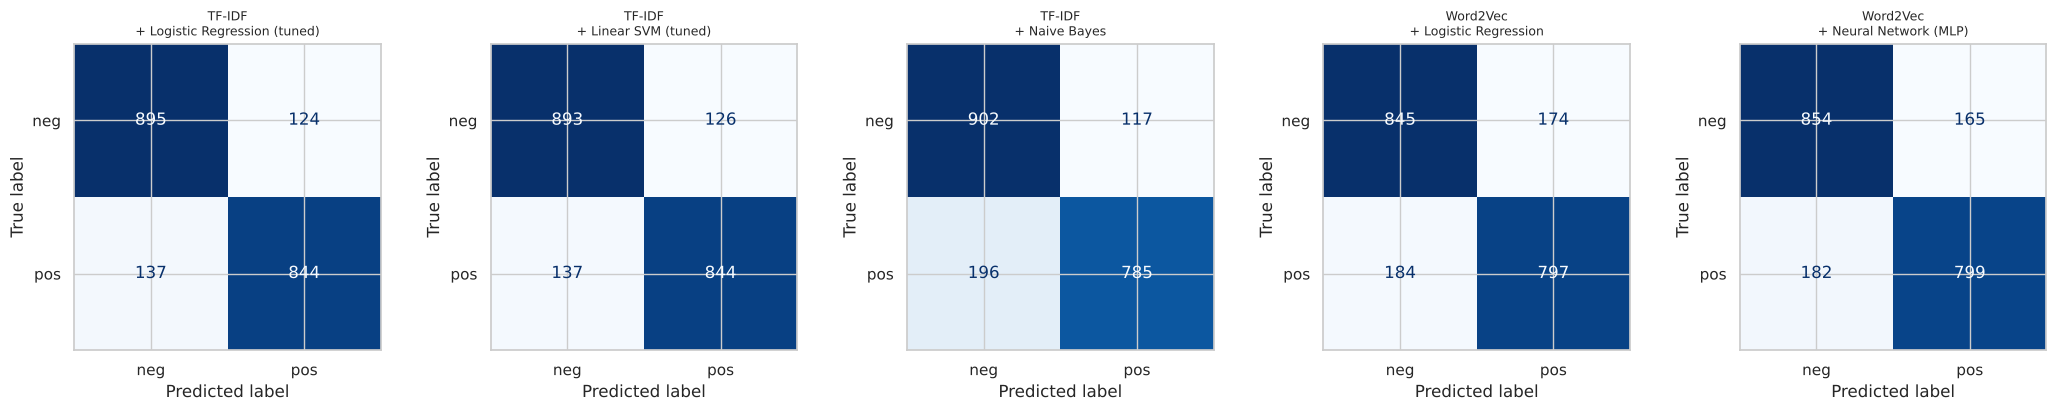

Detailed report - TF-IDF + Logistic Regression (tuned)
              precision    recall  f1-score   support

    negative     0.8672    0.8783    0.8727      1019
    positive     0.8719    0.8603    0.8661       981

    accuracy                         0.8695      2000
   macro avg     0.8696    0.8693    0.8694      2000
weighted avg     0.8695    0.8695    0.8695      2000



In [22]:
# Confusion matrices for all models
fig, axes = plt.subplots(1, len(preds), figsize=(4.2 * len(preds), 4))
for ax, (name, p) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p), display_labels=["neg", "pos"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name.replace(" + ", "\n+ "), fontsize=9)
plt.tight_layout(); plt.show()

print(f"Detailed report - {best_name}")
print(classification_report(y_test, preds[best_name], target_names=["negative", "positive"], digits=4))

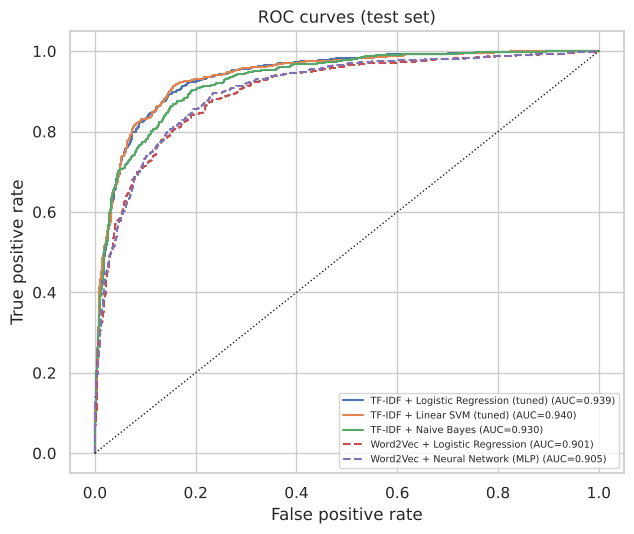

In [23]:
# ROC curves for models that provide a continuous score
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for name, m in {**final_models}.items():
    if hasattr(m, "predict_proba"):   score = m.predict_proba(X_test)[:, 1]
    else:                             score = m.decision_function(X_test)
    fpr, tpr, _ = roc_curve(y_test, score)
    ax.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, score):.3f})")
for name, m in w2v_models.items():
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(Xte_w2v)[:, 1])
    ax.plot(fpr, tpr, "--", label=f"{name} (AUC={roc_auc_score(y_test, m.predict_proba(Xte_w2v)[:, 1]):.3f})")
ax.plot([0, 1], [0, 1], "k:", lw=1); ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("ROC curves (test set)"); ax.legend(fontsize=7, loc="lower right"); plt.tight_layout(); plt.show()

**Discussion of results**

* The **TF-IDF + linear models** clearly outperform the Word2Vec-based models. Bag-of-n-gram features with a linear classifier are very strong for sentiment because individual sentiment words and short phrases are highly informative, and 10 000 reviews are too few to learn high-quality embeddings from scratch.
* The tuned **Logistic Regression** (86.95 % accuracy, F1 0.866) and tuned **Linear SVM** (86.85 %, F1 0.865) are statistically indistinguishable: the gap of 0.1 pt is far smaller than the CV standard deviation (about 0.8 pt). Tuning improved the untuned Logistic Regression by roughly 1 pt.
* **Naive Bayes** is precise (0.87) but has low recall (0.80): it under-predicts the positive class. It remains a very fast baseline.
* **Word2Vec** models reach 82–83 % on the test set, about 4 pts below TF-IDF. The nearest-neighbour check above also shows weak embeddings (e.g. *boring* has unrelated neighbours), which is expected from only 8 000 training reviews. The MLP did not beat the simple Logistic Regression on the same features.
* Errors are balanced between the two classes (see confusion matrices), consistent with the balanced dataset.

## 6. Interpretability & Error Analysis

### 6.1 What drives the prediction? (Logistic Regression coefficients)

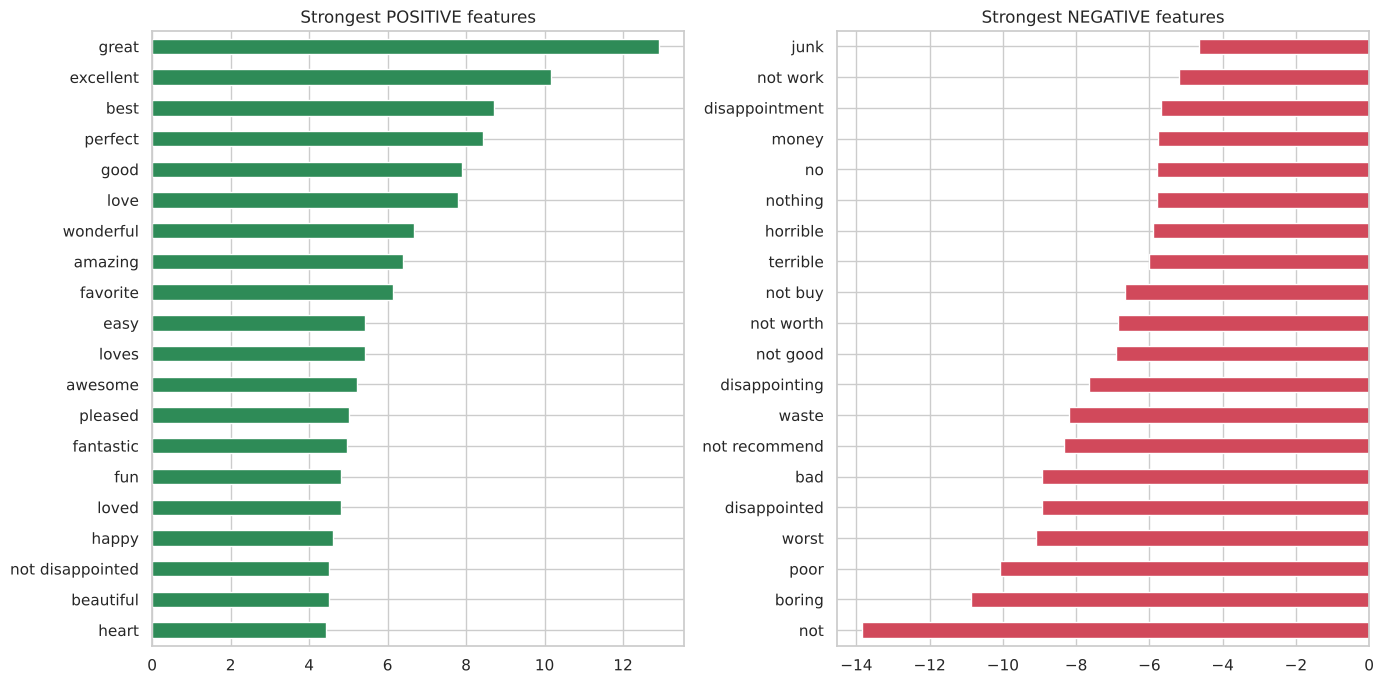

In [24]:
lr_best = final_models["TF-IDF + Logistic Regression (tuned)"]
vec, clf = lr_best.named_steps["vec"], lr_best.named_steps["clf"]
coef = pd.Series(clf.coef_[0], index=vec.get_feature_names_out()).sort_values()

fig, ax = plt.subplots(1, 2, figsize=(14, 7))
coef.tail(20).plot.barh(color="#2e8b57", ax=ax[0]); ax[0].set_title("Strongest POSITIVE features")
coef.head(20).plot.barh(color="#d1495b", ax=ax[1]); ax[1].set_title("Strongest NEGATIVE features")
plt.tight_layout(); plt.show()

The learned weights agree with the exploratory analysis: praise words and phrases push towards *positive*, while *waste*, *disappointed*, *not worth*, *poor* and *boring* push towards *negative*. The model is therefore learning sensible, explainable signals rather than artefacts.

### 6.2 Where does the model fail?

In [25]:
best_model = final_models["TF-IDF + Logistic Regression (tuned)"]
proba = best_model.predict_proba(X_test)[:, 1]
err = pd.DataFrame({"review": raw_test, "true": y_test.map({1: "pos", 0: "neg"}),
                    "pred": np.where(proba >= .5, "pos", "neg"), "p_pos": proba})
err["n_words"] = err["review"].str.split().str.len()
wrong = err[err["true"] != err["pred"]].copy()
wrong["confidence"] = (wrong["p_pos"] - .5).abs()

print(f"Misclassified: {len(wrong)} of {len(err)} ({len(wrong)/len(err):.1%})")
print("False positives (neg predicted pos):", ((wrong.true == 'neg')).sum(),
      "| False negatives (pos predicted neg):", ((wrong.true == 'pos')).sum())
print("\nMean length (words) - correct: %.0f | wrong: %.0f" %
      (err.loc[err.true == err.pred, "n_words"].mean(), wrong["n_words"].mean()))

pd.set_option("display.max_colwidth", 350)
print("\nMost confidently WRONG predictions:")
display(wrong.sort_values("confidence", ascending=False).head(6)[["true", "pred", "p_pos", "review"]].round(3))

Misclassified: 261 of 2000 (13.1%)
False positives (neg predicted pos): 124 | False negatives (pos predicted neg): 137

Mean length (words) - correct: 79 | wrong: 82

Most confidently WRONG predictions:


,true,pred,p_pos,review
3872,neg,pos,0.997,Mara Wilson: I Love Mara Wilson she is cute and beautiful.I also loved her in Matilda. I think that Matilda was beautiful.she is a good actress.she was a cute girl in Mrs.Doubtfire.I think that she was very good at that part
672,neg,pos,0.988,This is Disgusting: The German Pinscher is a wonderful Family pet and this type of comments makes them sound dangerous. I own 3 German Pinschers and they are wonderful pets. I resent this type of product.
1068,pos,neg,0.015,"Great show, but no need for blu-ray: I bought this show in the blu-ray edition expecting an incredible picture, but there was nothing special about it at all. The extras are nice but not what I buy DVDs for. There's no reason to waste your money buying the blu-ray edition. They didn't have HD technology when this special was produced and they c..."
8163,neg,pos,0.984,"Dismal: I guess the part I liked best was where Eleanor discovered that she was related to the ghost haunting the house. It was really believable. Tears came to my eyes it was so touching. Then, when the cherubs on the wall came to life, I was even more moved as there little souls finally were freed to go to heaven. That was really touching. I ..."
1967,neg,pos,0.983,"not too durable.: This was great as a Halloween Costume. however, after my daughter tried it on, one of the straps on the leg covers broke and the mask was too tight. Good for a one time use. My daughter enjoyed it."
5741,pos,neg,0.017,"Boring but useful: I must admit, this book is pretty lame in its organization and all. But there was still a load of stuff that I wouldn't have known, so there is some useful content here. (Heh...I couldn't have passed my test without it...)"


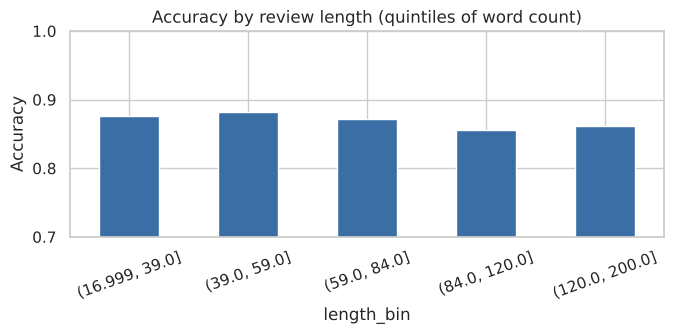

In [26]:
# Does accuracy depend on how long the review is?
err["correct"] = err["true"] == err["pred"]
err["length_bin"] = pd.qcut(err["n_words"], 5)
acc_by_len = err.groupby("length_bin", observed=True)["correct"].mean()
ax = acc_by_len.plot.bar(color="#3b6ea5", figsize=(7, 3.5), rot=20)
ax.set_ylim(0.7, 1); ax.set_ylabel("Accuracy"); ax.set_title("Accuracy by review length (quintiles of word count)")
plt.tight_layout(); plt.show()

**Error-analysis insights**

* The model makes 13 % errors, split evenly between false positives (124) and false negatives (137).
* The most confident mistakes include **suspect labels** (e.g. the “Mara Wilson” review is labelled negative although the text is entirely praise; this is exactly the text-vs-rating conflict described in the business problem) and **mixed or ironic reviews** (e.g. “Great show, but no need for blu-ray” is labelled positive, but the body complains; the “German Pinscher” review has a negative title but a positive body).
* Accuracy is fairly stable across review lengths (roughly 85–88 %), with the two longest quintiles (above about 84 words) slightly lower, plausibly because long reviews more often mix positive and negative statements. The differences are small, so length is not a major driver of errors.
* A bag-of-n-grams model cannot understand sarcasm or long-range context. Contextual models (e.g. fine-tuned BERT) are the natural next step for these cases.

## 7. Final Pipeline and Business Use

The tuned Logistic Regression is chosen as the final model: it has the best CV accuracy (87.8 %) and best test accuracy/F1 (86.95 % / 0.866) - tied in practice with the Linear SVM - while being fast, fully explainable and producing probabilities (useful for confidence thresholds and alerts). We wrap preprocessing + model in one reusable function.

In [27]:
def predict_sentiment(reviews):
    """Classify raw review texts; returns label and probability of being positive."""
    if isinstance(reviews, str): reviews = [reviews]
    cleaned = [clean_text(r) for r in reviews]
    p = best_model.predict_proba(cleaned)[:, 1]
    return pd.DataFrame({"review": reviews, "sentiment": np.where(p >= .5, "positive", "negative"), "p_positive": p.round(3)})

samples = [
    "Absolutely love this! Great quality and fast delivery, highly recommend.",
    "Total waste of money. It stopped working after two days and support never replied.",
    "The story was not good, I was bored and disappointed.",
    "Not bad at all, I really enjoyed it.",
    "Okay product but the battery is poor and it is overpriced.",
]
pd.set_option("display.max_colwidth", 90)
predict_sentiment(samples)

,review,sentiment,p_positive
0,"Absolutely love this! Great quality and fast delivery, highly recommend.",positive,0.999
1,Total waste of money. It stopped working after two days and support never replied.,negative,0.002
2,"The story was not good, I was bored and disappointed.",negative,0.002
3,"Not bad at all, I really enjoyed it.",positive,0.517
4,Okay product but the battery is poor and it is overpriced.,negative,0.031


**Note:** the model handles clear negation (*“not good”* is negative), but scope-sensitive cases are borderline: *“Not bad at all, I really enjoyed it.”* is scored p = 0.52, a narrow correct call. Cases like this should go to low-confidence human review.

### Monitoring negative-feedback spikes (how the model would be used)

For each product, score incoming reviews and track the **daily share of reviews predicted negative**. A spike is flagged when it exceeds the baseline by more than the random variation expected for that daily volume. The dataset has no product ID or date, so the snippet below demonstrates the logic on a simulated stream built from real test reviews. We use a **p-chart** (a standard control chart for proportions), which accounts for the daily review volume.

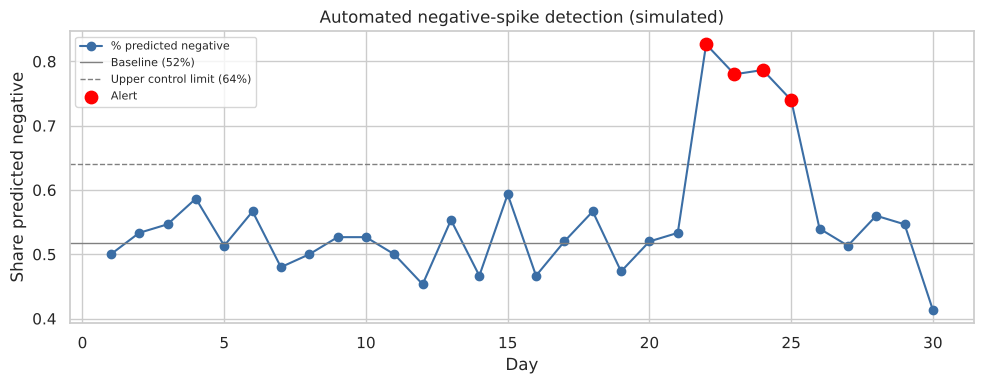

Alert days: [22, 23, 24, 25]


In [28]:
# Simulated 30-day stream for ONE product (150 reviews/day), built from real held-out reviews.
# Normal days: ~50 % of incoming reviews are truly negative. Days 22-25: a "bad batch" (~85 % negative).
rng = np.random.default_rng(SEED)
neg_pool, pos_pool = err[err.true == "neg"]["review"].tolist(), err[err.true == "pos"]["review"].tolist()
N_PER_DAY = 150
daily = []
for day in range(1, 31):
    p_neg = 0.85 if 22 <= day <= 25 else 0.50
    batch = [rng.choice(neg_pool) if rng.random() < p_neg else rng.choice(pos_pool) for _ in range(N_PER_DAY)]
    pred = predict_sentiment(batch)
    daily.append({"day": day, "pct_negative": (pred.sentiment == "negative").mean()})
daily = pd.DataFrame(daily)

# p-chart (statistical process control for proportions):
# centre line = average negative share in a 14-day baseline period,
# upper control limit (UCL) = centre + 3 * sqrt(p(1-p)/n). A day above the UCL is very unlikely by chance.
p_bar = daily.loc[daily.day <= 14, "pct_negative"].mean()
ucl = p_bar + 3 * np.sqrt(p_bar * (1 - p_bar) / N_PER_DAY)
daily["alert"] = daily["pct_negative"] > ucl

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(daily.day, daily.pct_negative, marker="o", color="#3b6ea5", label="% predicted negative")
ax.axhline(p_bar, color="grey", lw=1, label=f"Baseline ({p_bar:.0%})")
ax.axhline(ucl, color="grey", ls="--", lw=1, label=f"Upper control limit ({ucl:.0%})")
ax.scatter(daily.day[daily.alert], daily.pct_negative[daily.alert], color="red", zorder=5, s=80, label="Alert")
ax.set_xlabel("Day"); ax.set_ylabel("Share predicted negative"); ax.set_title("Automated negative-spike detection (simulated)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()
print("Alert days:", daily.day[daily.alert].tolist())

## 8. Conclusions, Recommendations and Limitations

In [29]:
final = test_table.round(4)
print("FINAL TEST-SET RESULTS")
display(final)

FINAL TEST-SET RESULTS


,accuracy,precision,recall,f1
model,,,,
TF-IDF + Logistic Regression (tuned),0.8695,0.8719,0.8603,0.8661
TF-IDF + Linear SVM (tuned),0.8685,0.8701,0.8603,0.8652
TF-IDF + Naive Bayes,0.8435,0.8703,0.8002,0.8338
Word2Vec + Neural Network (MLP),0.8265,0.8288,0.8145,0.8216
Word2Vec + Logistic Regression,0.8210,0.8208,0.8124,0.8166


### Summary of findings

1. **Data quality:** 10 000 reviews, no missing values and no duplicates; classes are almost perfectly balanced, so accuracy and F1 tell the same story.
2. **EDA:** length does not separate the classes; vocabulary does. Positive reviews use praise words (*great, love, excellent, best*), negative reviews use regret and failure words (*waste, disappointed, poor, boring, not*). Bigrams add useful context.
3. **Modelling:** TF-IDF (unigrams + bigrams) with a linear classifier is the best approach here: the tuned Logistic Regression reaches **86.95 % accuracy and F1 = 0.866** on the unseen test set (tuned SVM: 86.85 % / 0.865). Word2Vec trained on only 10 k reviews is about 4 pts weaker (≈82–83 %), as expected for a small corpus.
4. **Robustness:** the CV standard deviation is below 1 pt, and CV accuracy (87.8 %) is within about 1 pt of the test accuracy (86.95 %), so the estimate is stable. The slightly lower test figure is normal after tuning on the CV folds. Per-class precision/recall are balanced (about 0.86–0.87).
5. **Interpretability:** coefficients are intuitive, which makes the system easy to explain to non-technical stakeholders.

### Business recommendations
* Deploy the model to score every incoming review and track the **share of negative reviews per product per day**; alert on statistically significant jumps.
* Route reviews predicted negative with **high confidence** to customer support first, and surface the top negative n-grams per product (e.g. *poor quality, stopped working*) to the product team.
* Send **low-confidence** predictions (probability near 0.5, often mixed reviews) to human review.

### Limitations & future work
* Only ~10 k reviews; most are about media products (books, music, films), so performance may drop on other categories (electronics, clothing).
* Binary labels ignore neutral and mixed reviews; sarcasm and negation scope are only partially captured by n-grams.
* **Next steps:** fine-tune a transformer such as BERT/DistilBERT (contextual models usually outperform bag-of-words on sentiment, but this was not tested here), use pre-trained embeddings (GloVe, fastText), add a neutral class, and train on more data from all product categories.